In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/dataset_part_1_cleaned.csv")

print("Dataset shape:", df.shape)
print(df.columns.tolist())
display(df.head())

Dataset shape: (90, 17)
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,4535.0,LEO,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.0,LEO,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.0,ISS,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.0,PO,VAFB SLC 4E,False Ocean,1,False,False,False,Unknown,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.0,GTO,CCSFS SLC 40,None None,1,False,False,False,Unknown,1.0,0,B1004,-80.577366,28.561857


In [2]:
date_cols = [
    col for col in df.columns
    if "date" in col.lower()
]

print("Possible date columns:", date_cols)

Possible date columns: ['Date']


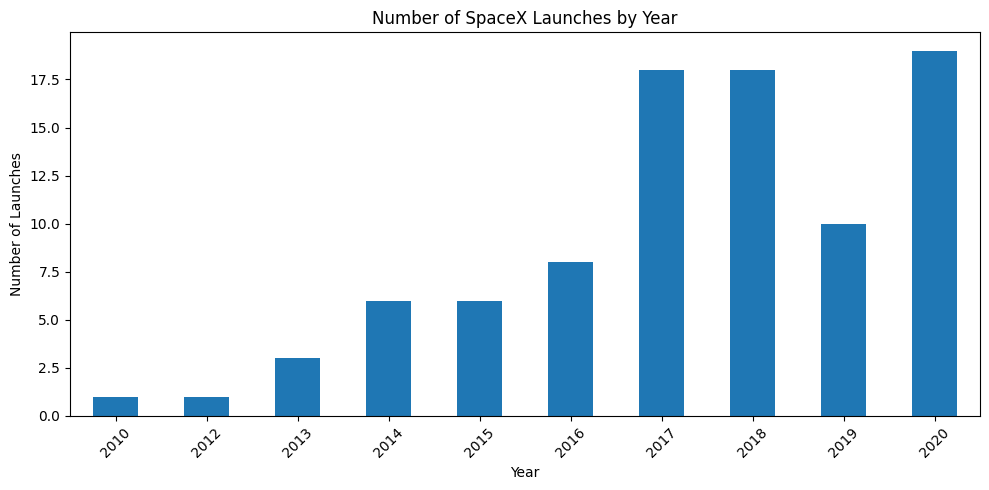

In [3]:
date_col = "Date"  # Replace with the actual column name

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df["Year"] = df[date_col].dt.year

launches_by_year = df.groupby("Year").size()

launches_by_year.plot(kind="bar", figsize=(10, 5))
plt.title("Number of SpaceX Launches by Year")
plt.xlabel("Year")
plt.ylabel("Number of Launches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Payload column: PayloadMass


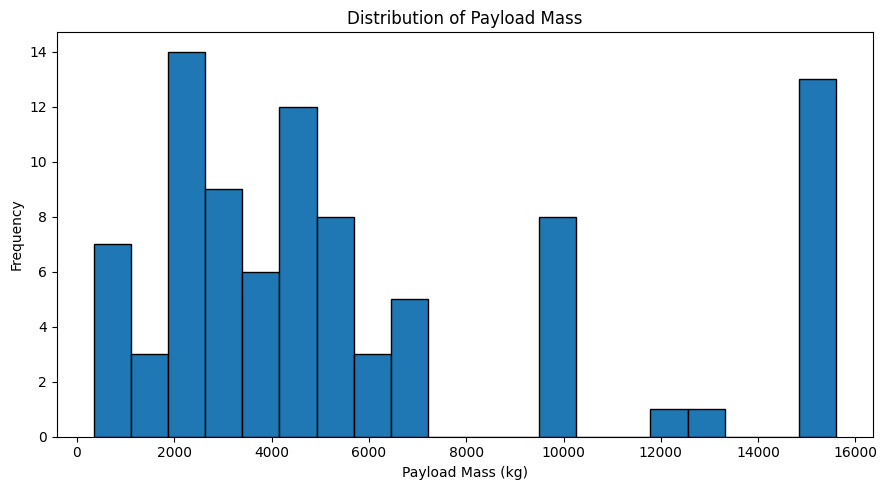

In [4]:
payload_col = next(
    (col for col in df.columns if "payloadmass" in col.lower()
     or "payload_mass" in col.lower()),
    None
)

print("Payload column:", payload_col)

if payload_col:
    df[payload_col].plot(
        kind="hist", bins=20, figsize=(9, 5), edgecolor="black"
    )
    plt.title("Distribution of Payload Mass")
    plt.xlabel("Payload Mass (kg)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("No payload-mass column found. Check the column names.")

Launch site column: LaunchSite


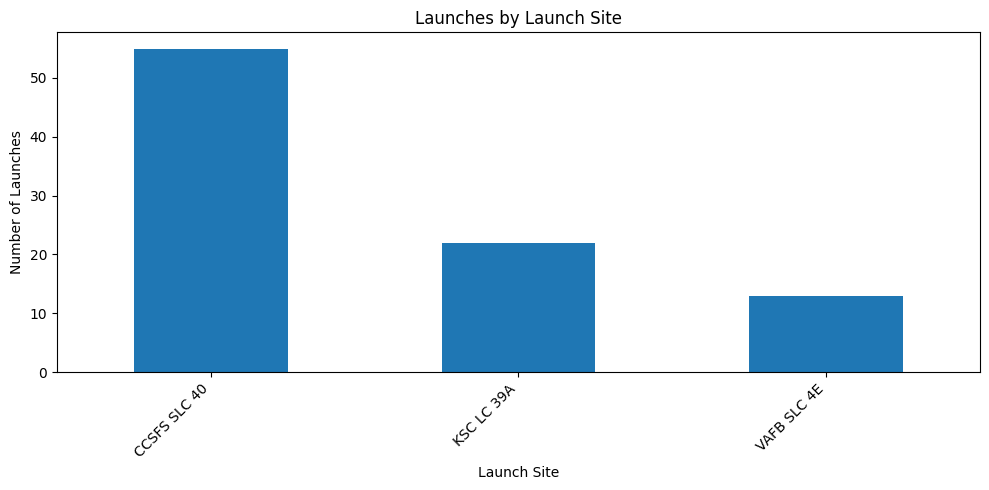

In [5]:
site_col = next(
    (col for col in df.columns if "launchsite" in col.lower()
     or "launch_site" in col.lower()),
    None
)

print("Launch site column:", site_col)

if site_col:
    df[site_col].value_counts().plot(
        kind="bar", figsize=(10, 5)
    )
    plt.title("Launches by Launch Site")
    plt.xlabel("Launch Site")
    plt.ylabel("Number of Launches")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No launch-site column found. Check the column names.")

Outcome column: Outcome


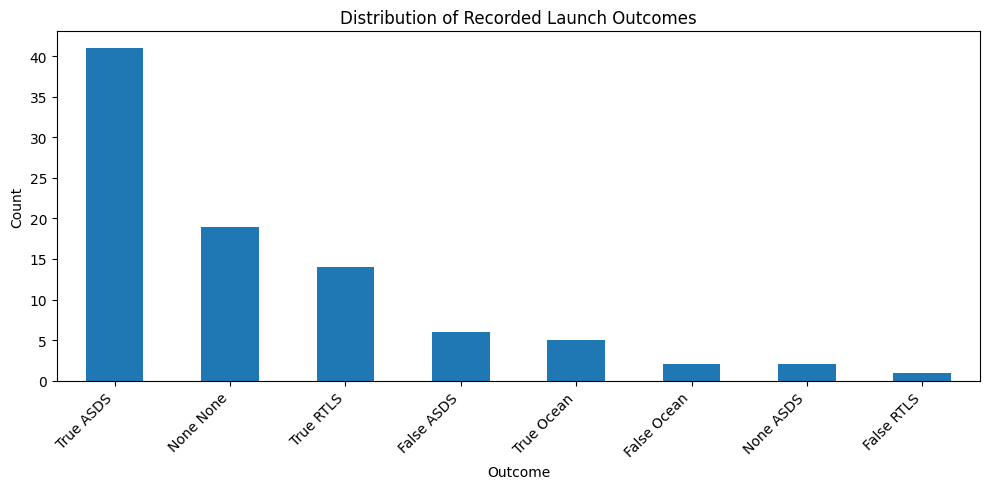

In [6]:
outcome_col = next(
    (col for col in df.columns if "outcome" in col.lower()),
    None
)

print("Outcome column:", outcome_col)

if outcome_col:
    df[outcome_col].value_counts().head(10).plot(
        kind="bar", figsize=(10, 5)
    )
    plt.title("Distribution of Recorded Launch Outcomes")
    plt.xlabel("Outcome")
    plt.ylabel("Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No outcome column found in this dataset.")